# Evaluación de SqueezeNet v1.1 (pesos de ImageNet) — 5 clases de residuos

Este notebook mide qué tan bien clasifica el modelo **SqueezeNet v1.1** ya entrenado, usando el set de **prueba** (`data/raw/waste_classification/test`). No entrena nada: solo carga el modelo y analiza sus predicciones.

**Qué se obtiene:**
1. Accuracy y loss globales.
2. Matriz de confusión y reporte de clasificación (precision, recall, F1).
3. Ejemplos visuales de imágenes mal clasificadas.
4. Accuracy por clase.

**Modelo evaluado:** `models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras` (generado por `entrenamiento_SqueezeNet.ipynb`).

> 📁 Este notebook vive en `notebooks/SqueezeNet/`, por eso las rutas parten de `Path("../..")` (dos niveles arriba = raíz del proyecto) y los modelos se leen/guardan en `models/SqueezeNet/`.

### Importación de librerías

Herramientas que se usan para evaluar el modelo:

* **`numpy`:** operaciones con arreglos (por ejemplo, elegir la clase con mayor probabilidad con `argmax`).
* **`matplotlib` y `seaborn`:** gráficas; `seaborn.heatmap` dibuja la matriz de confusión.
* **`tensorflow` / `load_model`:** carga el modelo `.keras` ya entrenado.
* **`ImageDataGenerator`:** lee las imágenes de prueba desde carpetas.
* **`classification_report` y `confusion_matrix` (scikit-learn):** calculan las métricas detalladas por clase.
* **`pathlib.Path`:** rutas que funcionan igual en Windows, Linux y Mac.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

2026-10-17 10:29:57.547484: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 10:29:58.044511: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-17 10:30:00.968965: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Configuración de rutas

Definimos de dónde se leen los datos y el modelo, y dónde se guardan las gráficas.

* **`BASE_DIR = Path("../..")`:** raíz del proyecto (dos niveles arriba de `notebooks/SqueezeNet/`).
* **`DATA_DIR`:** `data/raw/waste_classification/test`, el set de **prueba**. Son imágenes que el modelo nunca usó para ajustar sus pesos.
* **`MODEL_PATH`:** `models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras`, generado por `entrenamiento_SqueezeNet.ipynb`.
* **`FIGURES_DIR`:** `reports/figures/`, donde se guardan las figuras para el reporte.
* **`FIGURES_DIR.mkdir(...)`:** crea la carpeta de figuras si no existe.

In [2]:
# --- 1. CONFIGURACIÓN DE RUTAS (Compatible Windows/Linux) ---
BASE_DIR = Path("../..")
DATA_DIR = BASE_DIR / "data" / "raw" / "waste_classification" / "test"
MODELS_DIR = BASE_DIR / "models" / "SqueezeNet"
FIGURES_DIR = BASE_DIR / "reports" / "figures"

# Creamos la carpeta de figuras por si no existe
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Modelo generado por entrenamiento_SqueezeNet.ipynb
MODEL_PATH = MODELS_DIR / "modelo_residuos_SqueezeNet_imagenet.keras"

### Verificación de archivos y carga del modelo

Antes de hacer cualquier cálculo comprobamos que todo lo necesario existe, para obtener un error claro en vez de uno confuso más adelante.

1. Si no existe la carpeta de prueba, se detiene con `FileNotFoundError` indicando la ruta buscada.
2. Si no existe el modelo, se detiene pidiendo **ejecutar primero el notebook de entrenamiento**.
3. **Carga del modelo:** `load_model()` reconstruye la arquitectura (módulos *Fire* + cabecera) y los pesos desde el archivo `.keras`. Como se construyó íntegramente con capas nativas de Keras, se carga directamente sin requerir `custom_objects`.

In [3]:
# --- 2. VERIFICACIÓN Y CARGA ---
if not DATA_DIR.exists():
    raise FileNotFoundError(f"No se encontraron los datos en: {DATA_DIR}")
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo en: {MODEL_PATH}. ¡Ejecuta el entrenamiento primero!")

print("Rutas verificadas.")
print(f"Cargando modelo desde: {MODEL_PATH}")

model = load_model(MODEL_PATH)
print("✅ Modelo SqueezeNet v1.1 (ImageNet) cargado exitosamente.")

Rutas verificadas.
Cargando modelo desde: ../../models/SqueezeNet/modelo_residuos_SqueezeNet_imagenet.keras


I0000 00:00:1792254601.985653    9251 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2270 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


✅ Modelo SqueezeNet v1.1 (ImageNet) cargado exitosamente.


### Preparación del set de prueba

Creamos un generador que lee las imágenes de `test/` exactamente igual que durante el entrenamiento, pero **sin Data Augmentation**: queremos evaluar las fotos tal como son.

* **`IMG_SIZE = (224, 224)`:** mismo tamaño que en el entrenamiento.
* **`BATCH_SIZE = 32`:** cuántas imágenes se procesan a la vez. En evaluación no afecta el resultado, solo la velocidad y la memoria usada.
* **Preprocesamiento:** no se aplica `rescale` porque el modelo SqueezeNet trae su capa `Normalization` de ImageNet integrada al inicio.
* **`shuffle=False` (¡importante!):** mantiene las imágenes en orden. Así la posición *i* de las predicciones corresponde a la etiqueta real *i* de `test_gen.classes`; si se mezclaran, las métricas saldrían mal.
* **Nombres de las clases:** se obtienen de `test_gen.class_indices` (orden alfabético de las carpetas).

In [4]:
# --- 3. PREPARACIÓN DE DATOS (Set de Prueba) ---
# Usamos las mismas dimensiones que en el entrenamiento
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Sin Data Augmentation y sin rescale: el modelo trae su preprocesamiento integrado
datagen = ImageDataGenerator()

print("Generando set de validación...")
test_gen = datagen.flow_from_directory(
    str(DATA_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # ¡IMPORTANTE! No mezclar para que coincidan las etiquetas con la predicción
)

class_names = list(test_gen.class_indices.keys())
print(f"Clases detectadas: {len(class_names)} -> {class_names}")

Generando set de validación...
Found 4534 images belonging to 5 classes.
Clases detectadas: 5 -> ['aluminio', 'carton', 'otros', 'plastico', 'vidrio']


### Evaluación global (`model.evaluate`)

Pasamos todo el set de prueba por el modelo y obtenemos dos números resumen:

* **Pérdida (loss):** el error promedio (`categorical_crossentropy`). Cuanto más bajo, mejor.
* **Precisión (accuracy):** porcentaje de imágenes clasificadas correctamente.

Es la "calificación final" del modelo, pero no dice **en qué** se equivoca. Para eso están las celdas siguientes.

In [5]:
# --- 4. EVALUACIÓN ESTÁNDAR ---
print("Evaluando el modelo con los datos de prueba...")
loss, accuracy = model.evaluate(test_gen)

print(f"\nResultados Finales:")
print(f"   Pérdida (Loss): {loss:.4f}")
print(f"   Precisión (Accuracy): {accuracy*100:.2f}%")

Evaluando el modelo con los datos de prueba...


/home/jesus/Documentos/GitHub/EntrenamientoIA/.venv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
2026-10-17 10:36:43.332224: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f205800f1f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-17 10:36:43.332241: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Ti Laptop GPU, Compute Capability 8.6
2026-10-17 10:36:43.378404: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-17 10:36:43.719676: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92501


  1/142 ━━━━━━━━━━━━━━━━━━━━ 10:08 4s/step - accuracy: 0.7812 - loss: 0.8648

I0000 00:00:1792255006.310458    9489 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


142/142 ━━━━━━━━━━━━━━━━━━━━ 24s 140ms/step - accuracy: 0.9155 - loss: 0.2996

Resultados Finales:
   Pérdida (Loss): 0.2996
   Precisión (Accuracy): 91.55%


### Predicciones, matriz de confusión y reporte de clasificación

**1. Predicciones:** `model.predict` devuelve, para cada imagen, una probabilidad por clase. Con `np.argmax` nos quedamos con la clase más probable (`y_pred`) y la comparamos con la etiqueta real (`y_true`).

**2. Matriz de confusión:**
* Cada **fila** es la clase real y cada **columna** la clase que predijo el modelo.
* La **diagonal** son los aciertos; todo lo que está fuera son errores.
* Se guarda en `reports/figures/matriz_confusion_SqueezeNet_imagenet.png`.

**3. Reporte de clasificación (por clase):**
* **Precision:** de todo lo que el modelo dijo que era de esa clase, ¿cuánto lo era realmente?
* **Recall:** de todo lo que realmente era de esa clase, ¿cuánto encontró el modelo?
* **F1-score:** promedio armónico de precision y recall (un solo número que equilibra ambas).
* **Support:** cuántas imágenes reales hay de esa clase.
* **Macro avg** promedia las clases por igual; **weighted avg** pondera por la cantidad de imágenes de cada clase.

Generando predicciones detalladas...
142/142 ━━━━━━━━━━━━━━━━━━━━ 18s 114ms/step


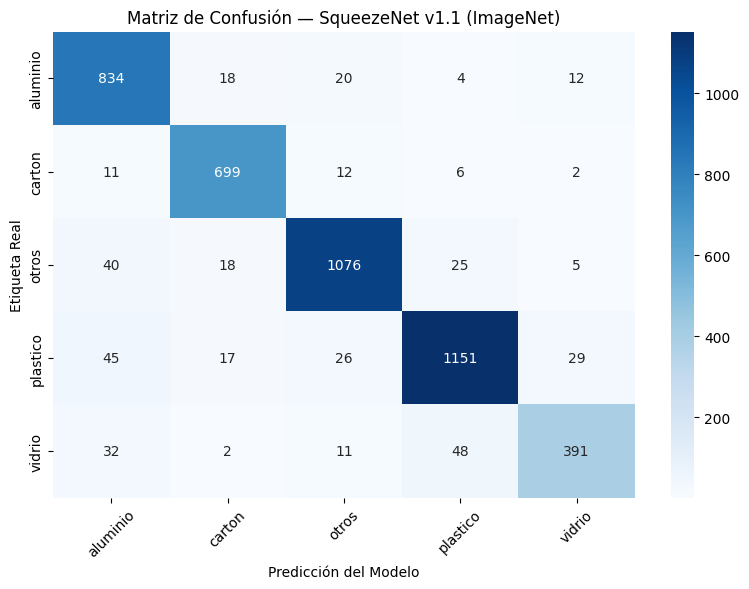


Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

    aluminio       0.87      0.94      0.90       888
      carton       0.93      0.96      0.94       730
       otros       0.94      0.92      0.93      1164
    plastico       0.93      0.91      0.92      1268
      vidrio       0.89      0.81      0.85       484

    accuracy                           0.92      4534
   macro avg       0.91      0.91      0.91      4534
weighted avg       0.92      0.92      0.92      4534



In [6]:
# --- 5. PREDICCIONES MULTICLASE ---
print("Generando predicciones detalladas...")
predictions = model.predict(test_gen)
y_pred = np.argmax(predictions, axis=1) # Tomamos la clase con mayor probabilidad
y_true = test_gen.classes               # Las etiquetas reales

# --- MATRIZ DE CONFUSIÓN ---
# Cada fila representa la clase real, cada columna la clase predicha.
# Los valores en la diagonal son aciertos; fuera de ella, errores.
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Matriz de Confusión — SqueezeNet v1.1 (ImageNet)')
plt.ylabel('Etiqueta Real')
plt.xlabel('Predicción del Modelo')
plt.xticks(rotation=45)
plt.tight_layout()
save_path = FIGURES_DIR / "matriz_confusion_SqueezeNet_imagenet.png"
plt.savefig(save_path, dpi=300)
plt.show()

# --- REPORTE DE CLASIFICACIÓN ---
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_true, y_pred, target_names=class_names))

### Matriz de confusión en texto

Imprime la misma matriz como arreglo de NumPy. Es útil para copiar los números exactos al reporte. El script `tests/comparar_modelos.py` lee esta salida directamente del notebook para armar la tabla comparativa entre modelos.

In [7]:
# La matriz en texto plano la lee tests/comparar_modelos.py para armar la tabla comparativa
print(cm)

[[ 834   18   20    4   12]
 [  11  699   12    6    2]
 [  40   18 1076   25    5]
 [  45   17   26 1151   29]
 [  32    2   11   48  391]]


### Conteo de errores

`np.where(y_pred != y_true)` devuelve los índices de las imágenes mal clasificadas. Con ellos calculamos cuántos errores hubo y volvemos a obtener la accuracy de forma manual (debe coincidir con la de `model.evaluate`).

Los índices quedan guardados en `errors` para inspeccionarlos visualmente en la celda siguiente.

In [8]:
# Buscamos dónde la predicción no coincide con la realidad
errors = np.where(y_pred != y_true)[0]

print(f"\nTotal de errores encontrados: {len(errors)} de {len(y_true)} imágenes reales.")
print(f"   Precisión Global (Accuracy): {1 - len(errors)/len(y_true):.2%}")


Total de errores encontrados: 383 de 4534 imágenes reales.
   Precisión Global (Accuracy): 91.55%


### Inspección visual de errores

Los números dicen *cuánto* se equivoca el modelo; ver las imágenes ayuda a entender *por qué*.

**¿Qué hace este código?**
1. Toma las rutas de las imágenes (`test_gen.filepaths`) en el mismo orden que las predicciones.
2. Muestra hasta **5 errores**, cada uno con su etiqueta real y la predicción del modelo (título en rojo).
3. Si no hubiera errores, lo indica con un mensaje.


Mostrando 5 ejemplos de clasificaciones incorrectas:


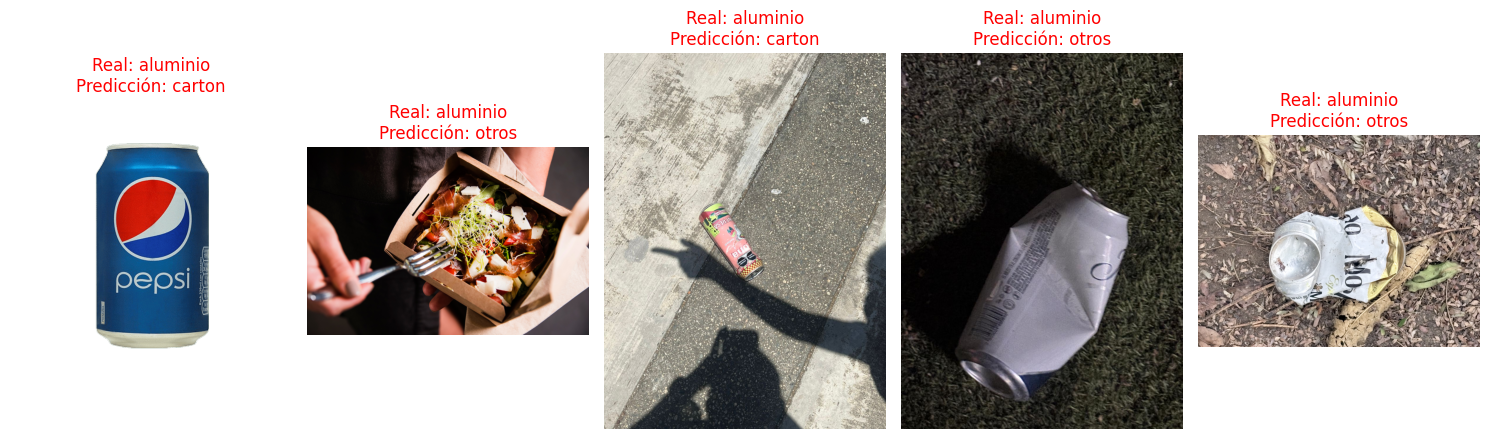

In [9]:
# Extraemos las rutas de los archivos reales y los nombres de las clases
filepaths = test_gen.filepaths
class_names = list(test_gen.class_indices.keys())

# Cuántos errores queremos ver en pantalla (máximo 5 para no saturar)
num_errores_a_mostrar = min(5, len(errors))

if num_errores_a_mostrar > 0:
    print(f"\nMostrando {num_errores_a_mostrar} ejemplos de clasificaciones incorrectas:")
    plt.figure(figsize=(15, 5))

    for i in range(num_errores_a_mostrar):
        idx = errors[i]
        img_path = filepaths[idx]

        etiqueta_real = class_names[y_true[idx]]
        etiqueta_predicha = class_names[y_pred[idx]]

        img = mpimg.imread(img_path)
        plt.subplot(1, num_errores_a_mostrar, i + 1)
        plt.imshow(img)
        plt.title(f"Real: {etiqueta_real}\nPredicción: {etiqueta_predicha}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("¡Excelente trabajo! El modelo no cometió ningún error en el set de pruebas.")

### Accuracy por clase

Para cada clase se filtran solo las imágenes que realmente pertenecen a ella (`mask = y_true == i`) y se calcula qué porcentaje acertó el modelo. Este valor es igual al **recall** de esa clase en el reporte de clasificación.

In [10]:
# Accuracy por clase — permite identificar qué categorías le cuestan más al modelo.
print("\nAccuracy por clase:")
print("-" * 35)
for i, class_name in enumerate(class_names):
    mask = y_true == i
    class_acc = np.mean(y_pred[mask] == y_true[mask])
    print(f"  {class_name:<12}: {class_acc*100:.2f}%")


Accuracy por clase:
-----------------------------------
  aluminio    : 93.92%
  carton      : 95.75%
  otros       : 92.44%
  plastico    : 90.77%
  vidrio      : 80.79%
